# 01 - Sensor branch

Trains the **sensor-only** RSL model on the engineered features produced by
`01sensor_preprocessing.ipynb` and `02_sensor_feature_engineering.ipynb`.

Target: `RemainingShelfLife = 11 - Day`, in days.

This notebook is the walkthrough; `scripts/train_sensor.py` is the same thing as a
runnable script.

In [1]:
import sys, warnings
sys.path.insert(0, "../scripts")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
import common as C, datasets as D, models as M
tf.get_logger().setLevel("ERROR")
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 1. Which columns may the model see?

`sensor_features.csv` has 58 columns and several of them are clocks rather than sensors.
Anything that encodes elapsed time reconstructs `RSL = 11 - Day` arithmetically, so the
model would score near-perfectly and learn nothing about spoilage - and a Raspberry Pi
handed an arbitrary sample could not supply those columns anyway.

In [2]:
raw = pd.read_csv(C.SENSOR_FEATURES_CSV)
num = raw.select_dtypes("number")
corr = num.corrwith(raw["Day"]).abs().sort_values(ascending=False)
print("Top correlations with Day (the target is 11 - Day):")
print(corr.head(10).round(4).to_string())
print()
print("Excluded as leakage:", C.LEAKAGE_COLUMNS)
print()
print(f"Model inputs ({len(C.feature_columns('full'))}):")
print(C.feature_columns("full"))

Top correlations with Day (the target is 11 - Day):
Day                            1.0000
Day_Of_Month                   0.9999
Elapsed_Time_Days              0.9908
Elapsed_Time_Hours             0.9908
Sl_No                          0.9683
Cumulative_Temperature         0.9683
Cumulative_Humidity            0.9678
Cumulative_Gas                 0.9678
Temperature_Gas_Interaction    0.4953
Temperature                    0.4243

Excluded as leakage: ['Sl_No', 'Day', 'Date', 'Timestamp', 'Year', 'Month', 'Day_Of_Month', 'Day_Of_Week', 'Elapsed_Time_Hours', 'Elapsed_Time_Days', 'Cumulative_Temperature', 'Cumulative_Humidity', 'Cumulative_Gas']

Model inputs (27):
['Temperature', 'Humidity', 'Gas', 'Temperature_Smoothed', 'Humidity_Smoothed', 'Gas_Smoothed', 'Temperature_Change', 'Humidity_Change', 'Gas_Change', 'Temperature_Rate', 'Humidity_Rate', 'Gas_Rate', 'Temperature_Rolling_Mean', 'Humidity_Rolling_Mean', 'Gas_Rolling_Mean', 'Temperature_Rolling_STD', 'Humidity_Rolling_STD', 'Gas_R

The `*_Level` band columns are excluded for a separate reason - they are not a function of
the reading they describe, so they cannot be recomputed on a Pi.

In [3]:
for ch in ["Temperature", "Humidity", "Gas"]:
    g = raw.groupby(f"{ch}_Level")[ch].agg(["min", "max", "count"]).sort_values("min")
    print(ch); print(g.to_string()); print()

Temperature
                     min    max  count
Temperature_Level                     
Moderate           25.62  29.31   3316

Humidity
                  min    max  count
Humidity_Level                     
Moderate        53.07  69.22   2920
High            58.98  67.51    396

Gas
             min    max  count
Gas_Level                     
Very_High  152.0  195.0    829
Low        179.0  179.0    829
Medium     179.0  187.0    829
High       184.0  184.0    829



## 2. Splits

Frames arrive roughly every 2 minutes, so neighbouring frames are near-duplicates. The
**blocked** split assigns whole 3-hour blocks to train/val/test so a frame and its twin
cannot straddle the boundary, and additionally **drops** any val/test row within 60
minutes of a training row - the `dropped` column below. 30-minute blocks were tried first
and were not enough: 93% of test rows still sat within half an hour of a train row. The
**random** split is kept only for comparison.

In [4]:
df, X, F, y, (tr, va, te) = D.load_all("blocked", "full")
print(f"samples: {len(df)}   sensor features: {X.shape[1]}")
print(f"train {tr.sum()}   val {va.sum()}   test {te.sum()}")
display(df.groupby("Day")[["split_blocked"]].value_counts().unstack(fill_value=0))

samples: 3067   sensor features: 27
train 1882   val 268   test 271


split_blocked,dropped,test,train,val
Day,,,,
1,33,0,78,0
2,154,31,432,30
3,106,114,379,29
4,55,56,159,57
5,53,0,56,53
6,110,27,461,55
7,80,30,223,27
9,53,13,87,17
10,0,0,1,0


## 3. Architecture

The penultimate layer, `sensor_embedding`, is the 64-d vector the fusion stage will
consume. The final `sensor_rsl` unit lets this branch stand alone as a complete model.

In [5]:
C.set_seeds()
sensor = M.compile_regressor(M.build_sensor_branch(X.shape[1]))
sensor.summary()

Model: "sensor_branch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor (InputLayer)             │ (None, 27)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_dense_1 (Dense)          │ (None, 128)            │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_bn_1                     │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_drop_1 (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_dense_2 (Dense)          │ (None, 96)             │        12,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_drop_2 (Dropout)         │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_embedding (Dense)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sensor_rsl (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,753 (88.88 KB)

 Trainable params: 22,497 (87.88 KB)

 Non-trainable params: 256 (1.00 KB)

stopped after 43 epochs


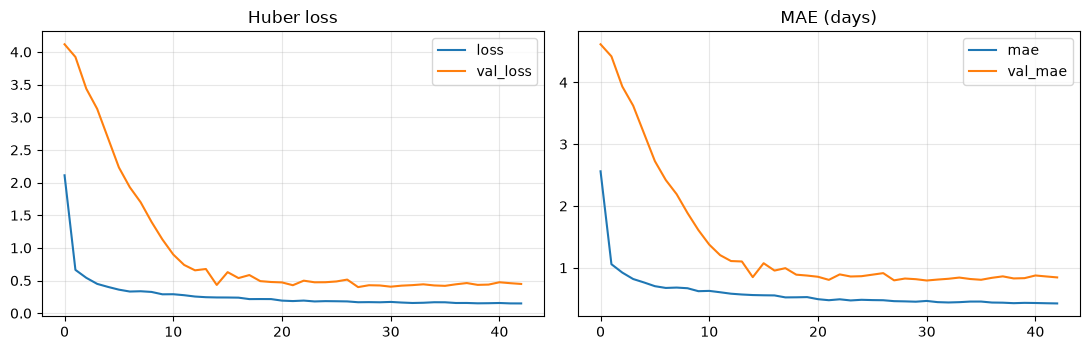

In [6]:
history = sensor.fit(
    X[tr], y[tr], validation_data=(X[va], y[va]),
    epochs=200, batch_size=64, callbacks=M.default_callbacks(), verbose=0,
)
print(f"stopped after {len(history.history['loss'])} epochs")
h = pd.DataFrame(history.history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Huber loss"); ax[0].grid(alpha=.3)
h[["mae", "val_mae"]].plot(ax=ax[1], title="MAE (days)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Held-out performance

In [7]:
for part, mask in [("train", tr), ("val", va), ("test", te)]:
    m = C.regression_metrics(y[mask], sensor.predict(X[mask], verbose=0))
    print(f"{part:>5}  MAE {m['MAE']:.3f}  RMSE {m['RMSE']:.3f}  R2 {m['R2']:.4f}")

train  MAE 0.650  RMSE 0.696  R2 0.8986
  val  MAE 0.795  RMSE 0.931  R2 0.7346
 test  MAE 0.640  RMSE 1.194  R2 0.5875


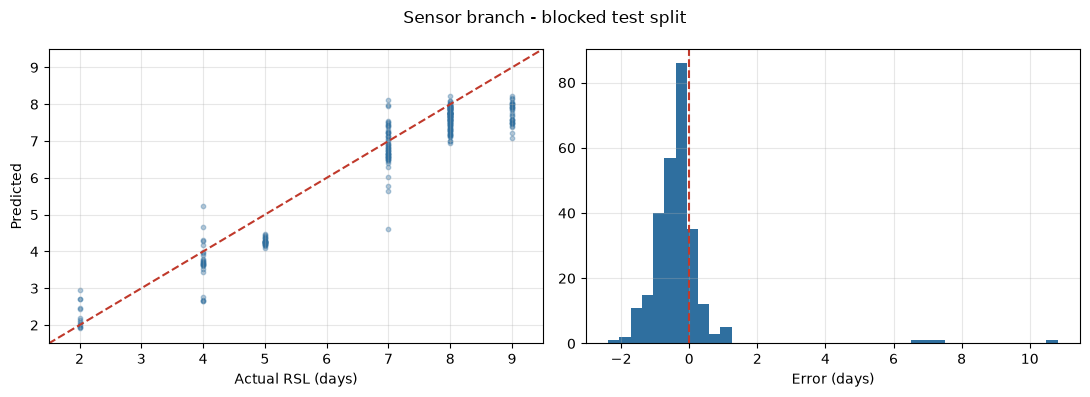

In [8]:
pred = sensor.predict(X[te], verbose=0).ravel()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y[te], pred, s=10, alpha=.35, color="#2f6f9f")
lims = [y[te].min()-.5, y[te].max()+.5]
ax[0].plot(lims, lims, "--", color="#c0392b"); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
ax[0].set_xlabel("Actual RSL (days)"); ax[0].set_ylabel("Predicted"); ax[0].grid(alpha=.3)
ax[1].hist(pred - y[te], bins=40, color="#2f6f9f"); ax[1].axvline(0, color="#c0392b", ls="--")
ax[1].set_xlabel("Error (days)"); ax[1].grid(alpha=.3)
plt.suptitle("Sensor branch - blocked test split"); plt.tight_layout(); plt.show()

Temperature, humidity and a single gas channel carry real but limited information about
spoilage stage: around 0.75 days of mean error even within a monitoring session. The image
branch (notebook 02) does considerably better, and notebook 03 shows the sensor branch is
also the one that generalises worst to a day it has never seen.